In [13]:
"""
EGH444 — NYUv2-style Segmentation: Dataloader + Trainable TorchVision Baseline
-----------------------------------------------------------------------------
This script provides a *training-ready* baseline for NYUv2-style RGB(+Depth) segmentation
using TorchVision models (FCN-ResNet50 or DeepLabV3-ResNet50).

Download dataset: https://drive.google.com/drive/folders/1RIa9t7Wi4krq0YcgjR3EWBxWWJedrYUl?usp=sharing
It follows a common directory/split structure:

NYUDepth/
  RGB/      {stem}.jpg|png
  Depth/    {stem}.png                # To be implemented by students
  Label/    {stem}.png                # semantic class IDs (NYUv2-40: 0..39)
  train.txt
  test.txt

Quick start (CPU):
  python EGH444_Segmentation_with_Dataloader_and_Training_NYU40.py \
      --data-root /path/to/NYUDepthv2 \
      --model deeplab \
      --num-classes 40 \
      --label-mode nyu40 \
      --device cpu \
      --epochs 2

Notes
- Default is **NYUv2-40** classes (0..39). Anything outside this range is set to 255 (ignore).
- You can set --label-mode raw to skip clamping if your masks already match your num-classes.
- Mixed precision is enabled on CUDA only; on CPU it runs FP32.
- Use --pretrained-backbone to *attempt* ImageNet backbone weights (will try to download if not available).
"""

import os
import argparse
import time
import random
from pathlib import Path
from typing import Tuple, Optional, Callable, Dict, Any

import numpy as np
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms.functional as TF
from torch.cuda.amp import autocast, GradScaler


# ----------------------------
# Config / Utilities
# ----------------------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
LABEL_MODE = "nyu40"  # module-global; set from args at runtime

def set_seeds(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def denorm_for_vis(x: torch.Tensor) -> np.ndarray:
    """Undo ImageNet norm: CHW tensor -> HWC uint8"""
    mean = torch.tensor(IMAGENET_MEAN, dtype=x.dtype, device=x.device)[:, None, None]
    std  = torch.tensor(IMAGENET_STD,  dtype=x.dtype, device=x.device)[:, None, None]
    img = (x * std + mean).clamp(0, 1).permute(1, 2, 0).cpu().numpy()
    return (img * 255).astype(np.uint8)

def colorize_ids(mask: np.ndarray) -> np.ndarray:
    K = int(mask.max()) + 1 if mask.size > 0 else 1
    rng = np.random.RandomState(0)
    cmap = rng.randint(0, 255, (max(K, 1), 3), dtype=np.uint8)
    idx = np.clip(mask, 0, K - 1)
    return cmap[idx]

def to_nyu40_ids(mask_np: np.ndarray) -> np.ndarray:
    """
    Ensure mask uses NYUv2-40 label space [0..39].
    Any pixel outside [0..39] is set to 255 (ignore).
    If your masks are already 0..39, this is a no-op; if not, out-of-range is safely ignored.
    """
    out = mask_np.astype(np.int64, copy=True)
    bad = (out < 0) | (out > 39)
    out[bad] = 255
    return out


# ----------------------------
# Dataset (NYUv2-style)
# ----------------------------
class NYUDepthDataset(Dataset):
    """
    Expects:
      base/
        RGB/{stem}.jpg|png
        Depth/{stem}.png
        Label/{stem}.png      # semantic class IDs
        train.txt / test.txt  # lines with filenames or paths; we parse .stem
    Returns tensors in transforms; here we read raw arrays.
    """
    def __init__(self, base_dir: str, split: str = "train",
                 transform: Optional[Callable] = None):
        self.base = Path(base_dir)
        self.rgb_dir  = self.base / "RGB"
        self.dep_dir  = self.base / "Depth"
        self.lbl_dir  = self.base / "Label"
        self.transform = transform

        with open(self.base / f"{split}.txt") as f:
            stems = [Path(line.split()[0]).stem for line in f if line.strip()]

        self.items = []
        for s in stems:
            rp = self.rgb_dir / f"{s}.jpg"
            if not rp.exists():
                rp = self.rgb_dir / f"{s}.png"
            dp = self.dep_dir / f"{s}.png"
            lp = self.lbl_dir / f"{s}.png"
            if rp.exists() and dp.exists() and lp.exists():
                self.items.append((s, rp, dp, lp))
        if not self.items:
            raise RuntimeError("No valid samples found. Check paths / split file.")

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        stem, rp, dp, lp = self.items[idx]

        rgb = cv2.imread(str(rp), cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

        depth = cv2.imread(str(dp), cv2.IMREAD_GRAYSCALE).astype(np.float32)
        label = cv2.imread(str(lp), cv2.IMREAD_GRAYSCALE).astype(np.int64)

        sample = {"rgb": rgb, "depth": depth, "mask": label, "id": stem}
        if self.transform is not None:
            sample = self.transform(sample)
        return sample


# ----------------------------
# Transforms
# ----------------------------
class SegTrainTransform:
    def __init__(self, size_hw: Tuple[int,int]=(240,320), hflip_p: float=0.5):
        self.H, self.W = size_hw
        self.hflip_p = hflip_p

    def __call__(self, sample: Dict[str,Any]) -> Dict[str,torch.Tensor]:
        rgb, depth, mask, sid = sample["rgb"], sample["depth"], sample["mask"], sample["id"]

        rgb   = cv2.resize(rgb,   (self.W, self.H), interpolation=cv2.INTER_LINEAR)
        depth = cv2.resize(depth, (self.W, self.H), interpolation=cv2.INTER_NEAREST)
        mask  = cv2.resize(mask,  (self.W, self.H), interpolation=cv2.INTER_NEAREST)
        if LABEL_MODE == 'nyu40':
            mask = to_nyu40_ids(mask)

        if random.random() < self.hflip_p:
            rgb   = np.ascontiguousarray(np.flip(rgb,  axis=1))
            depth = np.ascontiguousarray(np.flip(depth,axis=1))
            mask  = np.ascontiguousarray(np.flip(mask, axis=1))

        rgb_t = TF.normalize(TF.to_tensor(rgb), IMAGENET_MEAN, IMAGENET_STD)

        # Simple per-image depth normalization to [0,1] (kept for future RGBD work)
        valid = depth > 0
        if valid.any():
            dmin, dmax = float(depth[valid].min()), float(depth[valid].max())
            depth = (depth - dmin) / max(dmax - dmin, 1e-6)
        else:
            depth[:] = 0.0
        depth_t = torch.from_numpy(depth).unsqueeze(0).float()

        mask_t  = torch.from_numpy(mask).long()
        return {"image": rgb_t, "depth": depth_t, "mask": mask_t, "id": sid}

class SegEvalTransform:
    def __init__(self, size_hw: Tuple[int,int]=(240,320)):
        self.H, self.W = size_hw

    def __call__(self, sample: Dict[str,Any]) -> Dict[str,torch.Tensor]:
        rgb, depth, mask, sid = sample["rgb"], sample["depth"], sample["mask"], sample["id"]

        rgb   = cv2.resize(rgb,   (self.W, self.H), interpolation=cv2.INTER_LINEAR)
        depth = cv2.resize(depth, (self.W, self.H), interpolation=cv2.INTER_NEAREST)
        mask  = cv2.resize(mask,  (self.W, self.H), interpolation=cv2.INTER_NEAREST)
        if LABEL_MODE == 'nyu40':
            mask = to_nyu40_ids(mask)

        rgb_t = TF.normalize(TF.to_tensor(rgb), IMAGENET_MEAN, IMAGENET_STD)

        valid = depth > 0
        if valid.any():
            dmin, dmax = float(depth[valid].min()), float(depth[valid].max())
            depth = (depth - dmin) / max(dmax - dmin, 1e-6)
        else:
            depth[:] = 0.0
        depth_t = torch.from_numpy(depth).unsqueeze(0).float()

        mask_t  = torch.from_numpy(mask).long()
        return {"image": rgb_t, "depth": depth_t, "mask": mask_t, "id": sid}


# ----------------------------
# Models (TorchVision)
# ----------------------------
def build_fcn_resnet50(num_classes: int, pretrained_backbone: bool = False):
    """
    FCN-ResNet50.
    By default: NO downloads (weights=None, weights_backbone=None).
    If pretrained_backbone=True, attempt to load ImageNet backbone; gracefully fall back if it fails.
    """
    if pretrained_backbone:
        try:
            model = torchvision.models.segmentation.fcn_resnet50(weights=None, weights_backbone="IMAGENET1K_V1")
        except Exception as e:
            print("[Warn] Could not load pretrained backbone:", e)
            model = torchvision.models.segmentation.fcn_resnet50(weights=None, weights_backbone=None)
    else:
        model = torchvision.models.segmentation.fcn_resnet50(weights=None, weights_backbone=None)

    in_ch = model.classifier[4].in_channels
    model.classifier[4] = nn.Conv2d(in_ch, num_classes, kernel_size=1)
    return model

def build_deeplabv3_resnet50(num_classes: int, pretrained_backbone: bool = False):
    """
    DeepLabV3-ResNet50.
    By default: NO downloads (weights=None, weights_backbone=None).
    If pretrained_backbone=True, attempt to load ImageNet backbone; gracefully fall back if it fails.
    """
    if pretrained_backbone:
        try:
            model = torchvision.models.segmentation.deeplabv3_resnet50(weights=None, weights_backbone="IMAGENET1K_V1")
        except Exception as e:
            print("[Warn] Could not load pretrained backbone:", e)
            model = torchvision.models.segmentation.deeplabv3_resnet50(weights=None, weights_backbone=None)
    else:
        model = torchvision.models.segmentation.deeplabv3_resnet50(weights=None, weights_backbone=None)

    in_ch = model.classifier[4].in_channels
    model.classifier[4] = nn.Conv2d(in_ch, num_classes, kernel_size=1)
    return model


# ----------------------------
# Metrics
# ----------------------------
@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, num_classes: int, ignore_index: int = 255, device=None):
    model.eval()
    device = device or next(model.parameters()).device

    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    total, correct = 0, 0

    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        targets = batch["mask"].to(device, non_blocking=True)

        with autocast(enabled=(device.type == "cuda")):
            out = model(images)["out"]  # [B,C,H,W]
        pred = out.argmax(1)            # [B,H,W]

        valid = targets != ignore_index
        total += valid.sum().item()
        correct += (pred[valid] == targets[valid]).sum().item()

        p = pred[valid].view(-1).cpu().numpy()
        t = targets[valid].view(-1).cpu().numpy()
        for i in range(p.shape[0]):
            if 0 <= t[i] < num_classes and 0 <= p[i] < num_classes:
                cm[t[i], p[i]] += 1

    inter = np.diag(cm).astype(np.float64)
    gt    = cm.sum(1).astype(np.float64)
    pr    = cm.sum(0).astype(np.float64)
    union = gt + pr - inter
    iou   = inter / np.maximum(union, 1)
    miou  = float(np.nanmean(iou)) if iou.size > 0 else 0.0
    pixacc = float(correct / max(total, 1))

    return {"mIoU": miou, "PixelAcc": pixacc, "IoU_per_class": iou}


# ----------------------------
# Training
# ----------------------------
def train(args):
    global LABEL_MODE
    LABEL_MODE = args.label_mode

    set_seeds(args.seed)

    # Device selection: auto / cpu / cuda
    if args.device == "auto":
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        device = torch.device(args.device)
    print("Device:", device)
    print("Label mode:", LABEL_MODE)
    print("Num classes:", args.num_classes)

    train_tf = SegTrainTransform(size_hw=(args.size[0], args.size[1]), hflip_p=args.hflip)
    val_tf   = SegEvalTransform(size_hw=(args.size[0], args.size[1]))

    train_ds = NYUDepthDataset(args.data_root, split="train", transform=train_tf)
    val_ds   = NYUDepthDataset(args.data_root, split="test",  transform=val_tf)

    train_loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,
                              num_workers=args.workers, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=args.batch_size, shuffle=False,
                              num_workers=args.workers, pin_memory=True)

    if args.model == "fcn":
        model = build_fcn_resnet50(args.num_classes, pretrained_backbone=args.pretrained_backbone)
    elif args.model == "deeplab":
        model = build_deeplabv3_resnet50(args.num_classes, pretrained_backbone=args.pretrained_backbone)
    else:
        raise ValueError("Unknown --model. Choose from {fcn, deeplab}.")

    model = model.to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=args.ignore_index)
    optimizer = optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    scaler = GradScaler(enabled=(device.type == "cuda"))

    best_miou = -1.0

    for epoch in range(1, args.epochs + 1):
        model.train()
        running = 0.0
        tic = time.time()

        for it, batch in enumerate(train_loader, start=1):
            images = batch["image"].to(device, non_blocking=True)
            targets = batch["mask"].to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=(device.type == "cuda")):
                out = model(images)["out"]
                loss = criterion(out, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running += loss.item()
            if it % args.log_every == 0:
                print(f"[Epoch {epoch} | it {it:05d}] loss={running/args.log_every:.4f}")
                running = 0.0

        # ---- Validation ----
        metrics = evaluate(model, val_loader, args.num_classes, args.ignore_index, device=device)
        toc = time.time() - tic
        print(f"[Epoch {epoch}] mIoU={metrics['mIoU']:.4f}  PixelAcc={metrics['PixelAcc']:.4f}  (epoch time {toc:.1f}s)")

        if metrics["mIoU"] > best_miou:
            best_miou = metrics["mIoU"]
            ckpt = {
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "num_classes": args.num_classes,
                "model_name": args.model,
                "metrics": metrics,
                "size": args.size,
            }
            torch.save(ckpt, args.save_path)
            print(f"✓ Saved best checkpoint to {args.save_path} (mIoU={best_miou:.4f})")

    print("Training complete. Best mIoU:", best_miou)


# ----------------------------
# Optional: quick qualitative viz on val
# ----------------------------
@torch.no_grad()
def visualize_some(args, num_images: int = 2):
    global LABEL_MODE
    LABEL_MODE = args.label_mode

    if args.device == "auto":
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        device = torch.device(args.device)

    val_tf = SegEvalTransform(size_hw=(args.size[0], args.size[1]))
    val_ds = NYUDepthDataset(args.data_root, split="test", transform=val_tf)
    val_loader = DataLoader(val_ds, batch_size=10, shuffle=True, num_workers=0)

    if args.model == "fcn":
        model = build_fcn_resnet50(args.num_classes, pretrained_backbone=args.pretrained_backbone)
    else:
        model = build_deeplabv3_resnet50(args.num_classes, pretrained_backbone=args.pretrained_backbone)
    model = model.to(device)

    if os.path.isfile(args.save_path):
        ckpt = torch.load(args.save_path, map_location=device,weights_only=False)
        model.load_state_dict(ckpt["model_state"])
        print("Loaded checkpoint from", args.save_path)
    else:
        print("No checkpoint found at", args.save_path, "-- visualising with current weights.")

    model.eval()
    shown = 0
    for batch in val_loader:
        images = batch["image"].to(device)
        masks  = batch["mask"].to(device)
        with autocast(enabled=(device.type == "cuda")):
            out = model(images)["out"]
        pred = out.argmax(1)

        rgb = denorm_for_vis(images[0].cpu())
        gt  = masks[0].cpu().numpy()
        pd  = pred[0].cpu().numpy()

        plt.figure(figsize=(12,4))
        plt.subplot(1,3,1); plt.imshow(rgb); plt.axis("off"); plt.title("RGB")
        plt.subplot(1,3,2); plt.imshow(colorize_ids(gt)); plt.axis("off"); plt.title("GT")
        plt.subplot(1,3,3); plt.imshow(colorize_ids(pd)); plt.axis("off"); plt.title("Pred")
        plt.tight_layout(); plt.show()

        shown += 1
        if shown >= num_images:
            break


# ----------------------------
# CLI
# ----------------------------
def parse_args():
    p = argparse.ArgumentParser(description="EGH444 NYUv2 Depth segmentation training example")
    p.add_argument("--data-root", type=str, default='./NYUDepthv2',
                   help="Path to NYUDepth root (contains RGB/ Depth/ Label/ and train.txt/test.txt)")
    p.add_argument("--model", type=str, default="fcn", choices=["fcn","deeplab"],
                   help="Segmentation model")
    p.add_argument("--num-classes", type=int, default=41,
                   help="Number of semantic classes (40 for NYUv2-40)")
    p.add_argument("--label-mode", type=str, default="raw", choices=["nyu40","raw"],
               help="raw: use the dataset label IDs without clamping")
    p.add_argument("--device", type=str, default="auto", choices=["auto","cpu","cuda"],
                   help="Select device: auto (default), cpu, or cuda")
    p.add_argument("--pretrained-backbone", default=True,
                   help="Attempt to load ImageNet backbone weights (may download). Falls back if blocked.")

    p.add_argument("--epochs", type=int, default=2, help="Training epochs")
    p.add_argument("--batch-size", type=int, default=4, help="Batch size")
    p.add_argument("--workers", type=int, default=0, help="DataLoader workers")
    p.add_argument("--size", type=int, nargs=2, default=[240,320], metavar=("H","W"),
                   help="Input size (H W)")
    p.add_argument("--hflip", type=float, default=0.5,
                   help="Random horizontal flip probability (train)")
    p.add_argument("--lr", type=float, default=5e-4, help="Learning rate")
    p.add_argument("--weight-decay", type=float, default=1e-4, help="Weight decay")
    p.add_argument("--ignore-index", type=int, default=255,
                   help="Ignore index for loss/eval")
    p.add_argument("--save-path", type=str, default="checkpoint.pt",
                   help="Where to save best checkpoint")
    p.add_argument("--seed", type=int, default=42, help="Random seed")
    p.add_argument("--viz", action="store_true",
                   help="After training, show a few qualitative results")
    p.add_argument("--log-every", type=int, default=1,
               help="How often (in iterations) to log training loss")
    return p.parse_args(args=[])


if __name__ == "__main__":
    args = parse_args()
    train(args)
    if args.viz:
        visualize_some(args, num_images=2)


Device: cuda
Label mode: raw
Num classes: 41


/tmp/ipykernel_6084/805061084.py:333: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=(device.type == "cuda"))
/tmp/ipykernel_6084/805061084.py:347: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(device.type == "cuda")):


[Epoch 1 | it 00001] loss=3.6407
[Epoch 1 | it 00002] loss=3.2901
[Epoch 1 | it 00003] loss=3.4514
[Epoch 1 | it 00004] loss=3.1493
[Epoch 1 | it 00005] loss=3.4303
[Epoch 1 | it 00006] loss=2.9135
[Epoch 1 | it 00007] loss=2.5650
[Epoch 1 | it 00008] loss=2.6236
[Epoch 1 | it 00009] loss=2.4459
[Epoch 1 | it 00010] loss=2.3711
[Epoch 1 | it 00011] loss=2.0843
[Epoch 1 | it 00012] loss=2.5077
[Epoch 1 | it 00013] loss=2.1891
[Epoch 1 | it 00014] loss=2.7770
[Epoch 1 | it 00015] loss=2.9942
[Epoch 1 | it 00016] loss=2.3194
[Epoch 1 | it 00017] loss=3.0013
[Epoch 1 | it 00018] loss=2.2375
[Epoch 1 | it 00019] loss=2.4155
[Epoch 1 | it 00020] loss=2.1189
[Epoch 1 | it 00021] loss=2.1428
[Epoch 1 | it 00022] loss=2.2505
[Epoch 1 | it 00023] loss=1.9548
[Epoch 1 | it 00024] loss=2.2770
[Epoch 1 | it 00025] loss=2.2565
[Epoch 1 | it 00026] loss=2.2898
[Epoch 1 | it 00027] loss=2.5428
[Epoch 1 | it 00028] loss=1.6584
[Epoch 1 | it 00029] loss=2.1288
[Epoch 1 | it 00030] loss=2.2550
[Epoch 1 |

/tmp/ipykernel_6084/805061084.py:269: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(device.type == "cuda")):


[Epoch 1] mIoU=0.0652  PixelAcc=0.3944  (epoch time 40.3s)
✓ Saved best checkpoint to checkpoint.pt (mIoU=0.0652)
[Epoch 2 | it 00001] loss=2.2382
[Epoch 2 | it 00002] loss=2.3023
[Epoch 2 | it 00003] loss=2.1204
[Epoch 2 | it 00004] loss=1.7492
[Epoch 2 | it 00005] loss=1.8782
[Epoch 2 | it 00006] loss=2.2547
[Epoch 2 | it 00007] loss=1.8367
[Epoch 2 | it 00008] loss=2.0490
[Epoch 2 | it 00009] loss=2.2424
[Epoch 2 | it 00010] loss=1.7490
[Epoch 2 | it 00011] loss=1.7432
[Epoch 2 | it 00012] loss=1.9246
[Epoch 2 | it 00013] loss=1.6815
[Epoch 2 | it 00014] loss=1.8118
[Epoch 2 | it 00015] loss=2.0103
[Epoch 2 | it 00016] loss=1.4336
[Epoch 2 | it 00017] loss=1.6175
[Epoch 2 | it 00018] loss=1.8808
[Epoch 2 | it 00019] loss=2.1131
[Epoch 2 | it 00020] loss=1.7980
[Epoch 2 | it 00021] loss=1.5865
[Epoch 2 | it 00022] loss=2.2813
[Epoch 2 | it 00023] loss=1.6379
[Epoch 2 | it 00024] loss=2.1207
[Epoch 2 | it 00025] loss=1.5283
[Epoch 2 | it 00026] loss=1.9066
[Epoch 2 | it 00027] loss=1.

In [6]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory allocated:",
          round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
    print("GPU memory reserved:",
          round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

CUDA available: True
GPU: NVIDIA A16-4Q
GPU memory allocated: 0.12 GB
GPU memory reserved: 0.15 GB


Loaded checkpoint from checkpoint.pt


/tmp/ipykernel_6084/805061084.py:417: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(device.type == "cuda")):


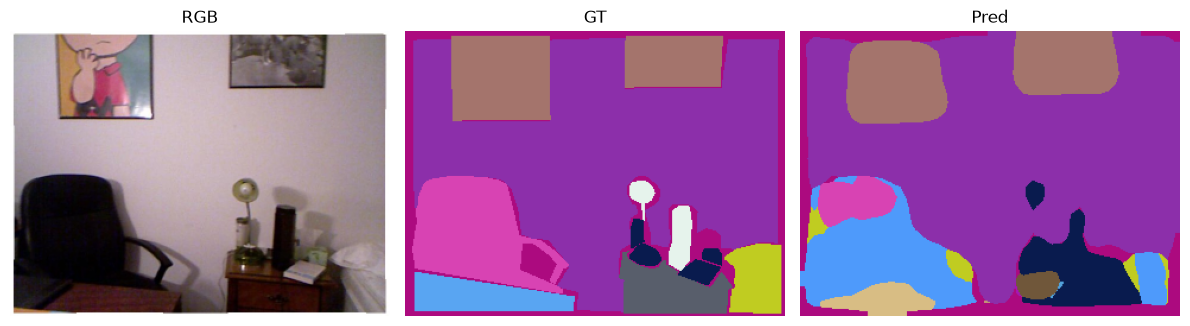

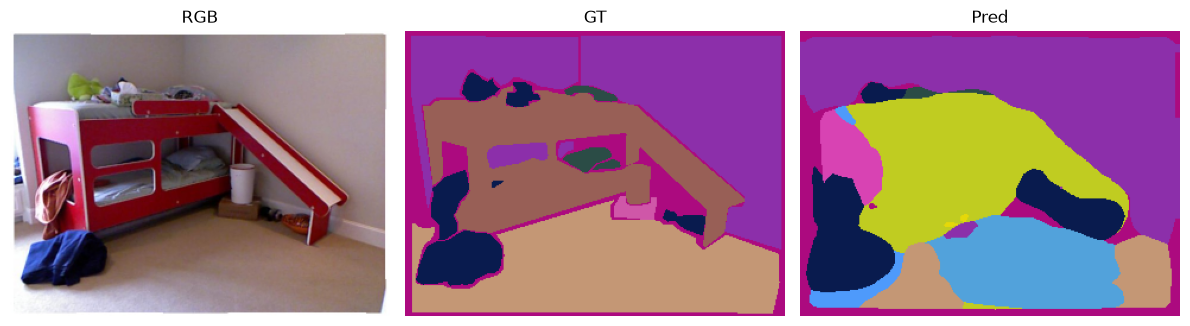

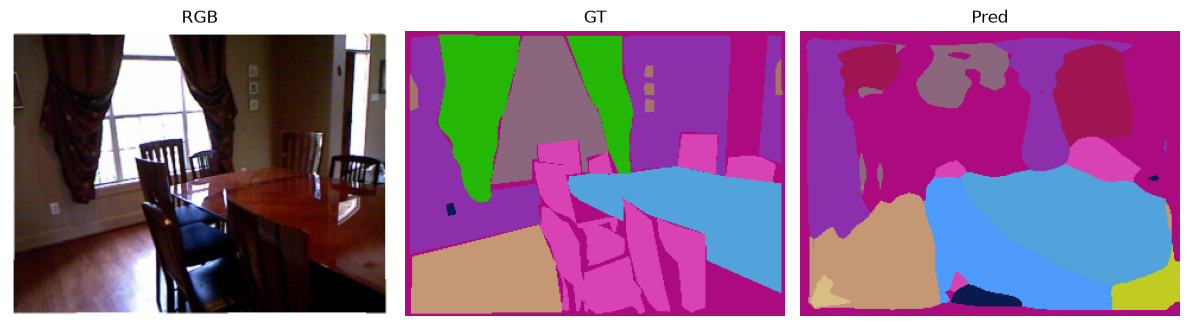

In [14]:
args = parse_args()

args.model = "fcn"
args.num_classes = 41
args.label_mode = "raw"
args.data_root = "./NYUDepthv2"
args.device = "cuda"
args.pretrained_backbone = True
args.save_path = "checkpoint.pt"
args.size = [240, 320]

visualize_some(args, num_images=3)

In [15]:

""" 10 EPOCS
EGH444 — NYUv2-style Segmentation: Dataloader + Trainable TorchVision Baseline
-----------------------------------------------------------------------------
This script provides a *training-ready* baseline for NYUv2-style RGB(+Depth) segmentation
using TorchVision models (FCN-ResNet50 or DeepLabV3-ResNet50).

Download dataset: https://drive.google.com/drive/folders/1RIa9t7Wi4krq0YcgjR3EWBxWWJedrYUl?usp=sharing
It follows a common directory/split structure:

NYUDepth/
  RGB/      {stem}.jpg|png
  Depth/    {stem}.png                # To be implemented by students
  Label/    {stem}.png                # semantic class IDs (NYUv2-40: 0..39)
  train.txt
  test.txt

Quick start (CPU):
  python EGH444_Segmentation_with_Dataloader_and_Training_NYU40.py \
      --data-root /path/to/NYUDepthv2 \
      --model deeplab \
      --num-classes 40 \
      --label-mode nyu40 \
      --device cpu \
      --epochs 2

Notes
- Default is **NYUv2-40** classes (0..39). Anything outside this range is set to 255 (ignore).
- You can set --label-mode raw to skip clamping if your masks already match your num-classes.
- Mixed precision is enabled on CUDA only; on CPU it runs FP32.
- Use --pretrained-backbone to *attempt* ImageNet backbone weights (will try to download if not available).
"""

import os
import argparse
import time
import random
from pathlib import Path
from typing import Tuple, Optional, Callable, Dict, Any

import numpy as np
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms.functional as TF
from torch.cuda.amp import autocast, GradScaler


# ----------------------------
# Config / Utilities
# ----------------------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
LABEL_MODE = "nyu40"  # module-global; set from args at runtime

def set_seeds(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def denorm_for_vis(x: torch.Tensor) -> np.ndarray:
    """Undo ImageNet norm: CHW tensor -> HWC uint8"""
    mean = torch.tensor(IMAGENET_MEAN, dtype=x.dtype, device=x.device)[:, None, None]
    std  = torch.tensor(IMAGENET_STD,  dtype=x.dtype, device=x.device)[:, None, None]
    img = (x * std + mean).clamp(0, 1).permute(1, 2, 0).cpu().numpy()
    return (img * 255).astype(np.uint8)

def colorize_ids(mask: np.ndarray) -> np.ndarray:
    K = int(mask.max()) + 1 if mask.size > 0 else 1
    rng = np.random.RandomState(0)
    cmap = rng.randint(0, 255, (max(K, 1), 3), dtype=np.uint8)
    idx = np.clip(mask, 0, K - 1)
    return cmap[idx]

def to_nyu40_ids(mask_np: np.ndarray) -> np.ndarray:
    """
    Ensure mask uses NYUv2-40 label space [0..39].
    Any pixel outside [0..39] is set to 255 (ignore).
    If your masks are already 0..39, this is a no-op; if not, out-of-range is safely ignored.
    """
    out = mask_np.astype(np.int64, copy=True)
    bad = (out < 0) | (out > 39)
    out[bad] = 255
    return out


# ----------------------------
# Dataset (NYUv2-style)
# ----------------------------
class NYUDepthDataset(Dataset):
    """
    Expects:
      base/
        RGB/{stem}.jpg|png
        Depth/{stem}.png
        Label/{stem}.png      # semantic class IDs
        train.txt / test.txt  # lines with filenames or paths; we parse .stem
    Returns tensors in transforms; here we read raw arrays.
    """
    def __init__(self, base_dir: str, split: str = "train",
                 transform: Optional[Callable] = None):
        self.base = Path(base_dir)
        self.rgb_dir  = self.base / "RGB"
        self.dep_dir  = self.base / "Depth"
        self.lbl_dir  = self.base / "Label"
        self.transform = transform

        with open(self.base / f"{split}.txt") as f:
            stems = [Path(line.split()[0]).stem for line in f if line.strip()]

        self.items = []
        for s in stems:
            rp = self.rgb_dir / f"{s}.jpg"
            if not rp.exists():
                rp = self.rgb_dir / f"{s}.png"
            dp = self.dep_dir / f"{s}.png"
            lp = self.lbl_dir / f"{s}.png"
            if rp.exists() and dp.exists() and lp.exists():
                self.items.append((s, rp, dp, lp))
        if not self.items:
            raise RuntimeError("No valid samples found. Check paths / split file.")

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        stem, rp, dp, lp = self.items[idx]

        rgb = cv2.imread(str(rp), cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

        depth = cv2.imread(str(dp), cv2.IMREAD_GRAYSCALE).astype(np.float32)
        label = cv2.imread(str(lp), cv2.IMREAD_GRAYSCALE).astype(np.int64)

        sample = {"rgb": rgb, "depth": depth, "mask": label, "id": stem}
        if self.transform is not None:
            sample = self.transform(sample)
        return sample


# ----------------------------
# Transforms
# ----------------------------
class SegTrainTransform:
    def __init__(self, size_hw: Tuple[int,int]=(240,320), hflip_p: float=0.5):
        self.H, self.W = size_hw
        self.hflip_p = hflip_p

    def __call__(self, sample: Dict[str,Any]) -> Dict[str,torch.Tensor]:
        rgb, depth, mask, sid = sample["rgb"], sample["depth"], sample["mask"], sample["id"]

        rgb   = cv2.resize(rgb,   (self.W, self.H), interpolation=cv2.INTER_LINEAR)
        depth = cv2.resize(depth, (self.W, self.H), interpolation=cv2.INTER_NEAREST)
        mask  = cv2.resize(mask,  (self.W, self.H), interpolation=cv2.INTER_NEAREST)
        if LABEL_MODE == 'nyu40':
            mask = to_nyu40_ids(mask)

        if random.random() < self.hflip_p:
            rgb   = np.ascontiguousarray(np.flip(rgb,  axis=1))
            depth = np.ascontiguousarray(np.flip(depth,axis=1))
            mask  = np.ascontiguousarray(np.flip(mask, axis=1))

        rgb_t = TF.normalize(TF.to_tensor(rgb), IMAGENET_MEAN, IMAGENET_STD)

        # Simple per-image depth normalization to [0,1] (kept for future RGBD work)
        valid = depth > 0
        if valid.any():
            dmin, dmax = float(depth[valid].min()), float(depth[valid].max())
            depth = (depth - dmin) / max(dmax - dmin, 1e-6)
        else:
            depth[:] = 0.0
        depth_t = torch.from_numpy(depth).unsqueeze(0).float()

        mask_t  = torch.from_numpy(mask).long()
        return {"image": rgb_t, "depth": depth_t, "mask": mask_t, "id": sid}

class SegEvalTransform:
    def __init__(self, size_hw: Tuple[int,int]=(240,320)):
        self.H, self.W = size_hw

    def __call__(self, sample: Dict[str,Any]) -> Dict[str,torch.Tensor]:
        rgb, depth, mask, sid = sample["rgb"], sample["depth"], sample["mask"], sample["id"]

        rgb   = cv2.resize(rgb,   (self.W, self.H), interpolation=cv2.INTER_LINEAR)
        depth = cv2.resize(depth, (self.W, self.H), interpolation=cv2.INTER_NEAREST)
        mask  = cv2.resize(mask,  (self.W, self.H), interpolation=cv2.INTER_NEAREST)
        if LABEL_MODE == 'nyu40':
            mask = to_nyu40_ids(mask)

        rgb_t = TF.normalize(TF.to_tensor(rgb), IMAGENET_MEAN, IMAGENET_STD)

        valid = depth > 0
        if valid.any():
            dmin, dmax = float(depth[valid].min()), float(depth[valid].max())
            depth = (depth - dmin) / max(dmax - dmin, 1e-6)
        else:
            depth[:] = 0.0
        depth_t = torch.from_numpy(depth).unsqueeze(0).float()

        mask_t  = torch.from_numpy(mask).long()
        return {"image": rgb_t, "depth": depth_t, "mask": mask_t, "id": sid}


# ----------------------------
# Models (TorchVision)
# ----------------------------
def build_fcn_resnet50(num_classes: int, pretrained_backbone: bool = False):
    """
    FCN-ResNet50.
    By default: NO downloads (weights=None, weights_backbone=None).
    If pretrained_backbone=True, attempt to load ImageNet backbone; gracefully fall back if it fails.
    """
    if pretrained_backbone:
        try:
            model = torchvision.models.segmentation.fcn_resnet50(weights=None, weights_backbone="IMAGENET1K_V1")
        except Exception as e:
            print("[Warn] Could not load pretrained backbone:", e)
            model = torchvision.models.segmentation.fcn_resnet50(weights=None, weights_backbone=None)
    else:
        model = torchvision.models.segmentation.fcn_resnet50(weights=None, weights_backbone=None)

    in_ch = model.classifier[4].in_channels
    model.classifier[4] = nn.Conv2d(in_ch, num_classes, kernel_size=1)
    return model

def build_deeplabv3_resnet50(num_classes: int, pretrained_backbone: bool = False):
    """
    DeepLabV3-ResNet50.
    By default: NO downloads (weights=None, weights_backbone=None).
    If pretrained_backbone=True, attempt to load ImageNet backbone; gracefully fall back if it fails.
    """
    if pretrained_backbone:
        try:
            model = torchvision.models.segmentation.deeplabv3_resnet50(weights=None, weights_backbone="IMAGENET1K_V1")
        except Exception as e:
            print("[Warn] Could not load pretrained backbone:", e)
            model = torchvision.models.segmentation.deeplabv3_resnet50(weights=None, weights_backbone=None)
    else:
        model = torchvision.models.segmentation.deeplabv3_resnet50(weights=None, weights_backbone=None)

    in_ch = model.classifier[4].in_channels
    model.classifier[4] = nn.Conv2d(in_ch, num_classes, kernel_size=1)
    return model


# ----------------------------
# Metrics
# ----------------------------
@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, num_classes: int, ignore_index: int = 255, device=None):
    model.eval()
    device = device or next(model.parameters()).device

    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    total, correct = 0, 0

    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        targets = batch["mask"].to(device, non_blocking=True)

        with autocast(enabled=(device.type == "cuda")):
            out = model(images)["out"]  # [B,C,H,W]
        pred = out.argmax(1)            # [B,H,W]

        valid = targets != ignore_index
        total += valid.sum().item()
        correct += (pred[valid] == targets[valid]).sum().item()

        p = pred[valid].view(-1).cpu().numpy()
        t = targets[valid].view(-1).cpu().numpy()
        for i in range(p.shape[0]):
            if 0 <= t[i] < num_classes and 0 <= p[i] < num_classes:
                cm[t[i], p[i]] += 1

    inter = np.diag(cm).astype(np.float64)
    gt    = cm.sum(1).astype(np.float64)
    pr    = cm.sum(0).astype(np.float64)
    union = gt + pr - inter
    iou   = inter / np.maximum(union, 1)
    miou  = float(np.nanmean(iou)) if iou.size > 0 else 0.0
    pixacc = float(correct / max(total, 1))

    return {"mIoU": miou, "PixelAcc": pixacc, "IoU_per_class": iou}


# ----------------------------
# Training
# ----------------------------
def train(args):
    global LABEL_MODE
    LABEL_MODE = args.label_mode

    set_seeds(args.seed)

    # Device selection: auto / cpu / cuda
    if args.device == "auto":
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        device = torch.device(args.device)
    print("Device:", device)
    print("Label mode:", LABEL_MODE)
    print("Num classes:", args.num_classes)

    train_tf = SegTrainTransform(size_hw=(args.size[0], args.size[1]), hflip_p=args.hflip)
    val_tf   = SegEvalTransform(size_hw=(args.size[0], args.size[1]))

    train_ds = NYUDepthDataset(args.data_root, split="train", transform=train_tf)
    val_ds   = NYUDepthDataset(args.data_root, split="test",  transform=val_tf)

    train_loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,
                              num_workers=args.workers, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=args.batch_size, shuffle=False,
                              num_workers=args.workers, pin_memory=True)

    if args.model == "fcn":
        model = build_fcn_resnet50(args.num_classes, pretrained_backbone=args.pretrained_backbone)
    elif args.model == "deeplab":
        model = build_deeplabv3_resnet50(args.num_classes, pretrained_backbone=args.pretrained_backbone)
    else:
        raise ValueError("Unknown --model. Choose from {fcn, deeplab}.")

    model = model.to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=args.ignore_index)
    optimizer = optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    scaler = GradScaler(enabled=(device.type == "cuda"))

    best_miou = -1.0

    for epoch in range(1, args.epochs + 1):
        model.train()
        running = 0.0
        tic = time.time()

        for it, batch in enumerate(train_loader, start=1):
            images = batch["image"].to(device, non_blocking=True)
            targets = batch["mask"].to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=(device.type == "cuda")):
                out = model(images)["out"]
                loss = criterion(out, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running += loss.item()
            if it % args.log_every == 0:
                print(f"[Epoch {epoch} | it {it:05d}] loss={running/args.log_every:.4f}")
                running = 0.0

        # ---- Validation ----
        metrics = evaluate(model, val_loader, args.num_classes, args.ignore_index, device=device)
        toc = time.time() - tic
        print(f"[Epoch {epoch}] mIoU={metrics['mIoU']:.4f}  PixelAcc={metrics['PixelAcc']:.4f}  (epoch time {toc:.1f}s)")

        if metrics["mIoU"] > best_miou:
            best_miou = metrics["mIoU"]
            ckpt = {
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "num_classes": args.num_classes,
                "model_name": args.model,
                "metrics": metrics,
                "size": args.size,
            }
            torch.save(ckpt, args.save_path)
            print(f"✓ Saved best checkpoint to {args.save_path} (mIoU={best_miou:.4f})")

    print("Training complete. Best mIoU:", best_miou)


# ----------------------------
# Optional: quick qualitative viz on val
# ----------------------------
@torch.no_grad()
def visualize_some(args, num_images: int = 2):
    global LABEL_MODE
    LABEL_MODE = args.label_mode

    if args.device == "auto":
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        device = torch.device(args.device)

    val_tf = SegEvalTransform(size_hw=(args.size[0], args.size[1]))
    val_ds = NYUDepthDataset(args.data_root, split="test", transform=val_tf)
    val_loader = DataLoader(val_ds, batch_size=10, shuffle=True, num_workers=0)

    if args.model == "fcn":
        model = build_fcn_resnet50(args.num_classes, pretrained_backbone=args.pretrained_backbone)
    else:
        model = build_deeplabv3_resnet50(args.num_classes, pretrained_backbone=args.pretrained_backbone)
    model = model.to(device)

    if os.path.isfile(args.save_path):
        ckpt = torch.load(args.save_path, map_location=device,weights_only=False)
        model.load_state_dict(ckpt["model_state"])
        print("Loaded checkpoint from", args.save_path)
    else:
        print("No checkpoint found at", args.save_path, "-- visualising with current weights.")

    model.eval()
    shown = 0
    for batch in val_loader:
        images = batch["image"].to(device)
        masks  = batch["mask"].to(device)
        with autocast(enabled=(device.type == "cuda")):
            out = model(images)["out"]
        pred = out.argmax(1)

        rgb = denorm_for_vis(images[0].cpu())
        gt  = masks[0].cpu().numpy()
        pd  = pred[0].cpu().numpy()

        plt.figure(figsize=(12,4))
        plt.subplot(1,3,1); plt.imshow(rgb); plt.axis("off"); plt.title("RGB")
        plt.subplot(1,3,2); plt.imshow(colorize_ids(gt)); plt.axis("off"); plt.title("GT")
        plt.subplot(1,3,3); plt.imshow(colorize_ids(pd)); plt.axis("off"); plt.title("Pred")
        plt.tight_layout(); plt.show()

        shown += 1
        if shown >= num_images:
            break


# ----------------------------
# CLI
# ----------------------------
def parse_args():
    p = argparse.ArgumentParser(description="EGH444 NYUv2 Depth segmentation training example")
    p.add_argument("--data-root", type=str, default='./NYUDepthv2',
                   help="Path to NYUDepth root (contains RGB/ Depth/ Label/ and train.txt/test.txt)")
    p.add_argument("--model", type=str, default="fcn", choices=["fcn","deeplab"],
                   help="Segmentation model")
    p.add_argument("--num-classes", type=int, default=41,
                   help="Number of semantic classes (40 for NYUv2-40)")
    p.add_argument("--label-mode", type=str, default="raw", choices=["nyu40","raw"],
               help="raw: use the dataset label IDs without clamping")
    p.add_argument("--device", type=str, default="auto", choices=["auto","cpu","cuda"],
                   help="Select device: auto (default), cpu, or cuda")
    p.add_argument("--pretrained-backbone", default=True,
                   help="Attempt to load ImageNet backbone weights (may download). Falls back if blocked.")

    p.add_argument("--epochs", type=int, default=10, help="Training epochs")
    p.add_argument("--batch-size", type=int, default=4, help="Batch size")
    p.add_argument("--workers", type=int, default=0, help="DataLoader workers")
    p.add_argument("--size", type=int, nargs=2, default=[240,320], metavar=("H","W"),
                   help="Input size (H W)")
    p.add_argument("--hflip", type=float, default=0.5,
                   help="Random horizontal flip probability (train)")
    p.add_argument("--lr", type=float, default=5e-4, help="Learning rate")
    p.add_argument("--weight-decay", type=float, default=1e-4, help="Weight decay")
    p.add_argument("--ignore-index", type=int, default=255,
                   help="Ignore index for loss/eval")
    p.add_argument("--save-path", type=str, default="checkpoint.pt",
                   help="Where to save best checkpoint")
    p.add_argument("--seed", type=int, default=42, help="Random seed")
    p.add_argument("--viz", action="store_true",
                   help="After training, show a few qualitative results")
    p.add_argument("--log-every", type=int, default=1,
               help="How often (in iterations) to log training loss")
    return p.parse_args(args=[])


if __name__ == "__main__":
    args = parse_args()
    train(args)
    if args.viz:
        visualize_some(args, num_images=2)

Device: cuda
Label mode: raw
Num classes: 41


/tmp/ipykernel_6084/3446597780.py:333: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=(device.type == "cuda"))
/tmp/ipykernel_6084/3446597780.py:347: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(device.type == "cuda")):


[Epoch 1 | it 00001] loss=3.6407
[Epoch 1 | it 00002] loss=3.2905
[Epoch 1 | it 00003] loss=3.4509
[Epoch 1 | it 00004] loss=3.1469
[Epoch 1 | it 00005] loss=3.4306
[Epoch 1 | it 00006] loss=2.9066
[Epoch 1 | it 00007] loss=2.5610
[Epoch 1 | it 00008] loss=2.6227
[Epoch 1 | it 00009] loss=2.4545
[Epoch 1 | it 00010] loss=2.3726
[Epoch 1 | it 00011] loss=2.0931
[Epoch 1 | it 00012] loss=2.5121
[Epoch 1 | it 00013] loss=2.1937
[Epoch 1 | it 00014] loss=2.7720
[Epoch 1 | it 00015] loss=3.0019
[Epoch 1 | it 00016] loss=2.3269
[Epoch 1 | it 00017] loss=2.9964
[Epoch 1 | it 00018] loss=2.2187
[Epoch 1 | it 00019] loss=2.4127
[Epoch 1 | it 00020] loss=2.1177
[Epoch 1 | it 00021] loss=2.1442
[Epoch 1 | it 00022] loss=2.2535
[Epoch 1 | it 00023] loss=1.9434
[Epoch 1 | it 00024] loss=2.2136
[Epoch 1 | it 00025] loss=2.2541
[Epoch 1 | it 00026] loss=2.3072
[Epoch 1 | it 00027] loss=2.5397
[Epoch 1 | it 00028] loss=1.6461
[Epoch 1 | it 00029] loss=2.1319
[Epoch 1 | it 00030] loss=2.2108
[Epoch 1 |

/tmp/ipykernel_6084/3446597780.py:269: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(device.type == "cuda")):


[Epoch 1] mIoU=0.0680  PixelAcc=0.4213  (epoch time 39.5s)
✓ Saved best checkpoint to checkpoint.pt (mIoU=0.0680)
[Epoch 2 | it 00001] loss=2.1968
[Epoch 2 | it 00002] loss=2.2793
[Epoch 2 | it 00003] loss=2.1434
[Epoch 2 | it 00004] loss=1.7024
[Epoch 2 | it 00005] loss=1.9101
[Epoch 2 | it 00006] loss=2.2877
[Epoch 2 | it 00007] loss=1.7762
[Epoch 2 | it 00008] loss=2.0473
[Epoch 2 | it 00009] loss=2.2724
[Epoch 2 | it 00010] loss=1.7917
[Epoch 2 | it 00011] loss=1.7583
[Epoch 2 | it 00012] loss=1.8707
[Epoch 2 | it 00013] loss=1.6744
[Epoch 2 | it 00014] loss=1.8424
[Epoch 2 | it 00015] loss=1.8658
[Epoch 2 | it 00016] loss=1.4600
[Epoch 2 | it 00017] loss=1.5982
[Epoch 2 | it 00018] loss=1.8967
[Epoch 2 | it 00019] loss=2.0844
[Epoch 2 | it 00020] loss=1.8033
[Epoch 2 | it 00021] loss=1.5686
[Epoch 2 | it 00022] loss=2.3153
[Epoch 2 | it 00023] loss=1.6657
[Epoch 2 | it 00024] loss=2.0534
[Epoch 2 | it 00025] loss=1.5782
[Epoch 2 | it 00026] loss=1.9122
[Epoch 2 | it 00027] loss=1.

Loaded checkpoint from checkpoint.pt


/tmp/ipykernel_6084/3446597780.py:417: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(device.type == "cuda")):


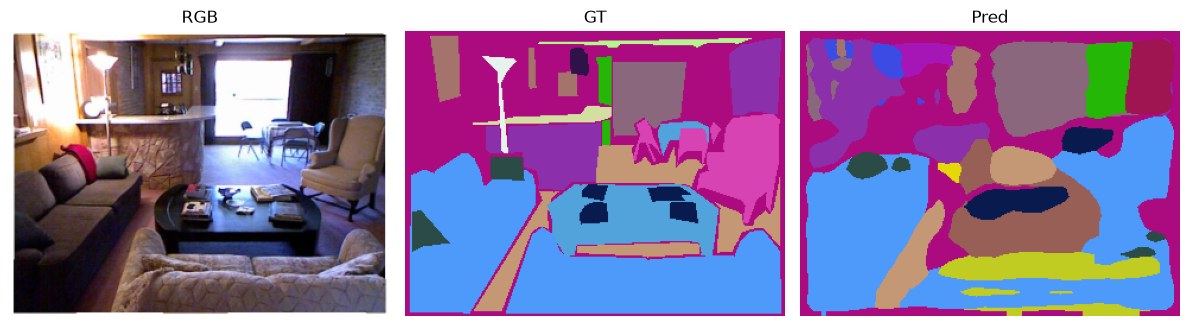

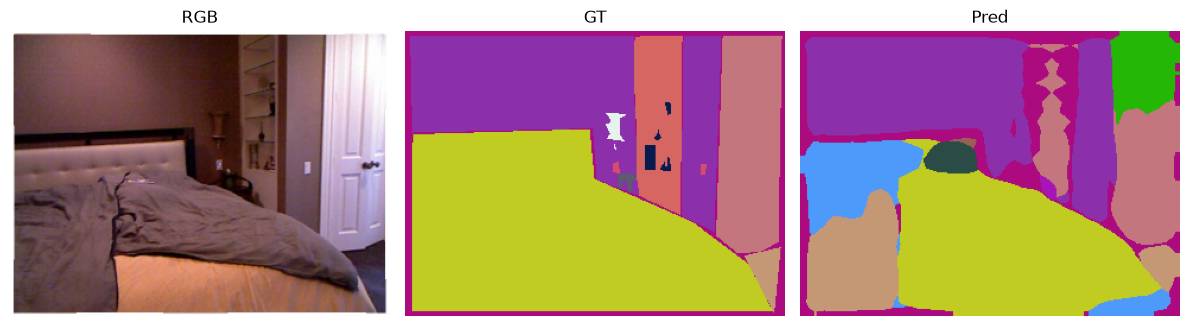

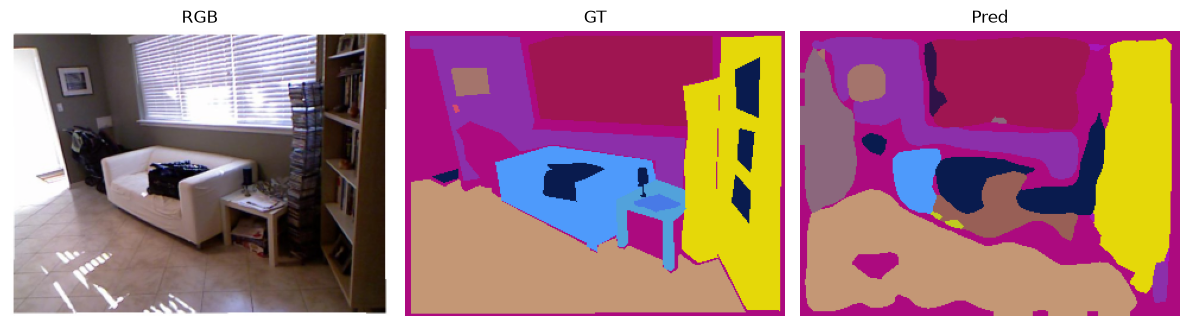

In [16]:
args = parse_args()

args.model = "fcn"
args.num_classes = 41
args.label_mode = "raw"
args.data_root = "./NYUDepthv2"
args.device = "cuda"
args.pretrained_backbone = True
args.save_path = "checkpoint.pt"
args.size = [240, 320]

visualize_some(args, num_images=3)

In [17]:
import torch

checkpoint = torch.load(
    "checkpoint.pt",
    map_location="cuda",
    weights_only=False
)

print("Best epoch:", checkpoint["epoch"])
print("Best mIoU:", checkpoint["metrics"]["mIoU"])
print("Best Pixel Accuracy:", checkpoint["metrics"]["PixelAcc"])

iou_per_class = checkpoint["metrics"]["IoU_per_class"]

print("\nIoU for each class:")
for class_id, iou in enumerate(iou_per_class):
    print(f"Class {class_id:2d}: IoU = {iou:.4f}")

Best epoch: 8
Best mIoU: 0.17537085357455057
Best Pixel Accuracy: 0.5399264475334448

IoU for each class:
Class  0: IoU = 0.3412
Class  1: IoU = 0.6526
Class  2: IoU = 0.6406
Class  3: IoU = 0.2560
Class  4: IoU = 0.3834
Class  5: IoU = 0.2318
Class  6: IoU = 0.3666
Class  7: IoU = 0.1609
Class  8: IoU = 0.1484
Class  9: IoU = 0.2583
Class 10: IoU = 0.1884
Class 11: IoU = 0.4574
Class 12: IoU = 0.2812
Class 13: IoU = 0.2402
Class 14: IoU = 0.0084
Class 15: IoU = 0.0000
Class 16: IoU = 0.3547
Class 17: IoU = 0.2645
Class 18: IoU = 0.2074
Class 19: IoU = 0.0099
Class 20: IoU = 0.2333
Class 21: IoU = 0.0971
Class 22: IoU = 0.3589
Class 23: IoU = 0.0399
Class 24: IoU = 0.0150
Class 25: IoU = 0.2913
Class 26: IoU = 0.0134
Class 27: IoU = 0.0000
Class 28: IoU = 0.0000
Class 29: IoU = 0.0478
Class 30: IoU = 0.0000
Class 31: IoU = 0.0096
Class 32: IoU = 0.1779
Class 33: IoU = 0.0000
Class 34: IoU = 0.0000
Class 35: IoU = 0.1889
Class 36: IoU = 0.0000
Class 37: IoU = 0.0000
Class 38: IoU = 0.05

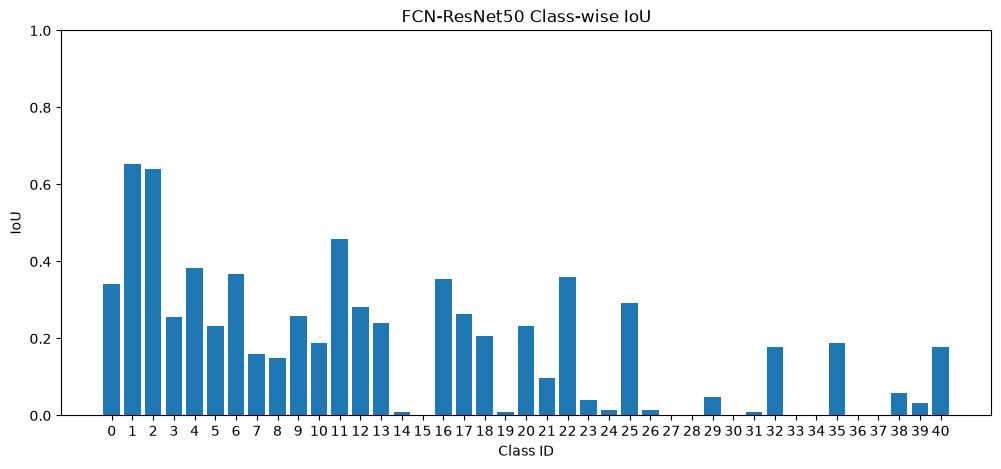

In [18]:
import matplotlib.pyplot as plt

class_ids = list(range(len(iou_per_class)))

plt.figure(figsize=(12, 5))
plt.bar(class_ids, iou_per_class)

plt.xlabel("Class ID")
plt.ylabel("IoU")
plt.title("FCN-ResNet50 Class-wise IoU")
plt.xticks(class_ids)
plt.ylim(0, 1)

plt.show()